In [ ]:
!nvidia-smi

Wed Nov 11 21:36:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
!pip -q install "monai[nibabel,tqdm]" matplotlib

In [ ]:
import os, json, glob
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import torch
import monai
from monai.apps import DecathlonDataset

print("PyTorch:", torch.__version__)
print("MONAI:", monai.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch: 2.14.1+cu130
MONAI: 1.6.1
GPU available: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ROOT = "/content/drive/MyDrive/liver_vessel_unet/data"
os.makedirs(ROOT, exist_ok=True)
print("Data folder:", ROOT)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/liver_vessel_unet/data


In [ ]:
# cache_rate=0.0: we only want to download here, not to load everything in memory
_ = DecathlonDataset(
    root_dir=ROOT,
    task="Task08_HepaticVessel",
    section="training",
    transform=(),
    download=True,
    cache_rate=0.0,
)
print(os.listdir(os.path.join(ROOT, "Task08_HepaticVessel")))

2026-11-11 21:56:30,143 - INFO - Verified 'Task08_HepaticVessel.tar', md5: 641d79e80ec66453921d997fbf12a29c.
2026-11-11 21:56:30,144 - INFO - File exists: /content/drive/MyDrive/liver_vessel_unet/data/Task08_HepaticVessel.tar, skipped downloading.
2026-11-11 21:56:30,147 - INFO - Non-empty folder exists in /content/drive/MyDrive/liver_vessel_unet/data/Task08_HepaticVessel, skipped extracting.
['._labelsTr', '._imagesTr', '._imagesTs', '._dataset.json', 'dataset.json', 'imagesTs', 'imagesTr', 'labelsTr']


In [ ]:
DATA_DIR = os.path.join(ROOT, "Task08_HepaticVessel")
with open(os.path.join(DATA_DIR, "dataset.json")) as f:
    info = json.load(f)

print("Name:", info.get("name"))
print("Modality:", info.get("modality"))
print("Labels:", info.get("labels"))     # check here what label 1 and 2 mean
print("Training cases:", info.get("numTraining"))

Name: HepaticVessel
Modality: {'0': 'CT'}
Labels: {'0': 'background', '1': 'Vessel', '2': 'Tumour'}
Training cases: 303


In [ ]:
images = sorted(glob.glob(os.path.join(DATA_DIR, "imagesTr", "*.nii.gz")))
labels = sorted(glob.glob(os.path.join(DATA_DIR, "labelsTr", "*.nii.gz")))
images = [p for p in images if not os.path.basename(p).startswith("._")]
labels = [p for p in labels if not os.path.basename(p).startswith("._")]
print(len(images), "images and", len(labels), "labels")

img_nii = nib.load(images[0])
lab_nii = nib.load(labels[0])
img = img_nii.get_fdata()
lab = lab_nii.get_fdata().astype(np.uint8)

print("Case:", os.path.basename(images[0]))
print("Image shape:", img.shape)
print("Voxel spacing (mm):", img_nii.header.get_zooms())
print("Intensity range (HU):", img.min(), "to", img.max())
print("Label values:", np.unique(lab))
for v in np.unique(lab):
    print(f"  label {v}: {(lab == v).sum()} voxels")

303 images and 303 labels
Case: hepaticvessel_001.nii.gz
Image shape: (512, 512, 49)
Voxel spacing (mm): (np.float32(0.917969), np.float32(0.917969), np.float32(5.0))
Intensity range (HU): -1024.0 to 1289.0
Label values: [0 1 2]
  label 0: 12835641 voxels
  label 1: 8887 voxels
  label 2: 528 voxels


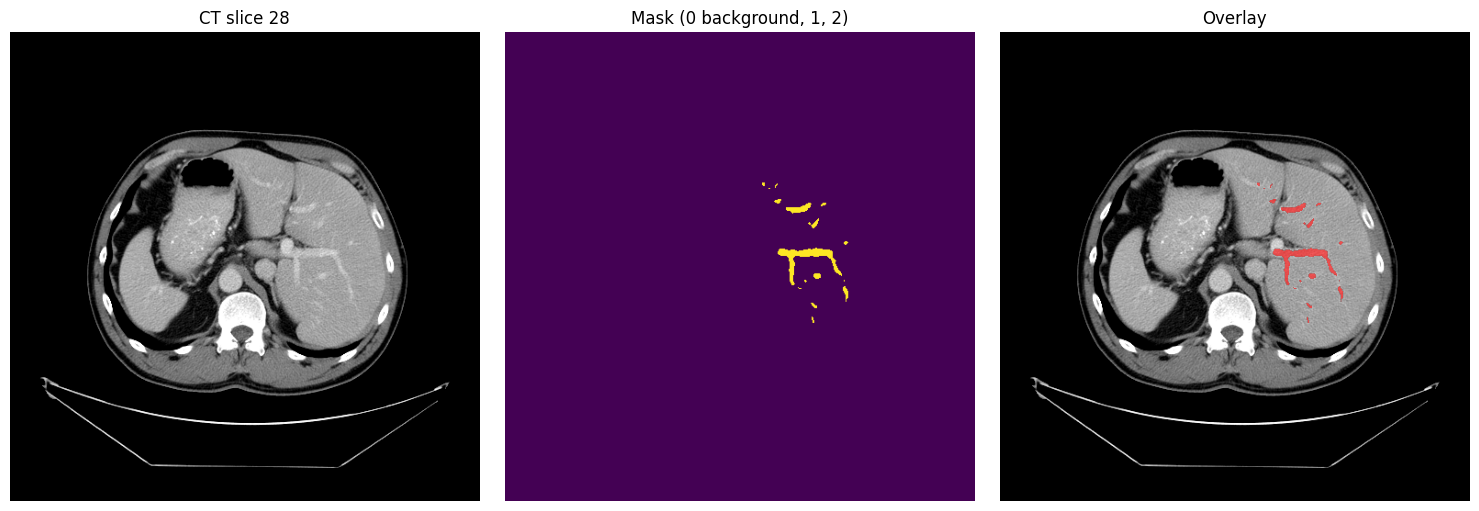

In [ ]:
# pick the slice with the most labelled voxels
z = int(np.argmax((lab > 0).sum(axis=(0, 1))))

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(np.rot90(img[:, :, z]), cmap="gray", vmin=-100, vmax=250)
ax[0].set_title(f"CT slice {z}")
ax[1].imshow(np.rot90(lab[:, :, z]), cmap="viridis")
ax[1].set_title("Mask (0 background, 1, 2)")
ax[2].imshow(np.rot90(img[:, :, z]), cmap="gray", vmin=-100, vmax=250)
ax[2].imshow(np.ma.masked_equal(np.rot90(lab[:, :, z]), 0), cmap="autumn", alpha=0.6)
ax[2].set_title("Overlay")
for a in ax: a.axis("off")
plt.tight_layout()
plt.show()